# Entrenamiento - detección de somnolencia

En este cuaderno se entrenan y comparan distintos modelos para clasificar el estado de una persona (de alerta a somnolencia) a partir del movimiento de los ojos, la boca y la cabeza, y en un fragmento de vídeo. Para esta detección, se toman como punto de partida las _features_ extraídas de UTA-RLDD en [`drowsiness_extraction.ipynb`](./drowsiness_extraction.ipynb).

Se comparan cinco modelos: un clasificador por **reglas**, tres modelos clásicos (**SVM RBF**, **Random Forest** y **Gradient Boosting**) y una red recurrente (**GRU**).

## Evaluación

Todos los modelos se evalúan en las mismas condiciones:

- **Datos:** cada vídeo se divide en ventanas de cierta longitud (por ejemplo 30s), y que avanzan de 10 en 10 s, agilizando el manejo de los datos.
- **Validación:** se usa el método 5-fold provisto por el _dataset_.
- **Métricas:** _accuracy_ y F1-macro, por ventana y por vídeo (mayoría entre sus ventanas).

## Índice

1. [Preparación](#1-preparación)
2. [Datos](#2-datos)
    - [2.1 Vídeos](#21-vídeos)
    - [2.2 Calibración por persona](#22-calibración-por-persona)
    - [2.3 Ventanas y _features_](#23-ventanas-y-features)
3. [Modelos y entrenamiento](#3-modelos-y-entrenamiento)
    - [3.1 Modelos](#31-modelos)
    - [3.2 Entrenamiento](#32-entrenamiento)
4. [Resultados](#4-resultados)
    - [4.1 Acierto](#41-acierto)
    - [4.2 Matrices de confusión](#42-matrices-de-confusión)
    - [4.3 Duración de la ventana](#43-duración-de-la-ventana)
    - [4.4 Importancia de las _features_](#44-importancia-de-las-features)
    - [4.5 Coste](#45-coste)
5. [Conclusiones](#5-conclusiones)

## 1. Preparación

Antes de ejecutar este _notebook_, es necesario haber ejecutado [`drowsiness_extraction.ipynb`](./drowsiness_extraction.ipynb), que crea las _features_ sobre las que trabajan los modelos.

In [1]:
import copy
import pickle
import sys
import time
from functools import lru_cache

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_class_weight
from torch import nn
from torch.utils.tensorboard import SummaryWriter

sys.path.insert(0, "..")
from common.benchmark import measure_latency
from common.classification_metrics import classification_metrics, plot_confusion_matrix
from common.drowsiness.classical import classical_models, fit_tuned
from common.drowsiness.model import DrowsinessGRU, SequencePredictor, VideoGRU
from common.drowsiness.videos import CLASSES
from common.drowsiness.windows import (WINDOW_FEATURES, as_columns, build_windows, calibration, default_baseline,
                                       normalise, window_features)
from common.experiment import DATA, RESULTS, ROOT, WEIGHTS, cached, load_config
from common.training import GPUBatchLoader, Trainer, seed_everything

cfg = load_config("drowsiness.yaml")
FRAMES_DIR = DATA / "uta_rldd" / "frames"
RESULTS_DIR = RESULTS / "drowsiness"
WEIGHTS_DIR = WEIGHTS / "drowsiness"
RUNS_DIR = ROOT / "runs" / "drowsiness"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

torch.backends.cudnn.benchmark = True
print(torch.cuda.get_device_name())

NVIDIA GeForce RTX 5080


## 2. Datos

### 2.1 Vídeos

Análisis de los vídeos del conjunto de datos:

In [15]:
videos = pd.read_csv(FRAMES_DIR / "index.csv")
FOLDS = sorted(videos["fold"].unique().tolist())
frames = {}
for video in videos.itertuples():
    data = joblib.load(FRAMES_DIR / f"{video.video}.joblib")
    frames[video.video] = as_columns(data["frames"], data["fps"], cfg.windows.fps)

display(videos.pivot_table(index="fold", columns="label", values="video", aggfunc="count", margins=True))
print(f"{videos['minutos'].sum() / 60:.1f} h de vídeo, {(videos['minutos'] * (1 - videos['sin_cara'])).sum() / 60:.1f} h con cara")

label,0,5,10,All
fold,,,,
1,12,12,12,36
2,12,12,12,36
3,12,12,13,37
4,12,12,12,36
5,12,12,13,37
All,60,60,62,182


31.6 h de vídeo, 31.4 h con cara


### 2.2 Calibración por persona

Puesto que los modelos de detección de cansancio basan parte de sus razonamientos en el estudio de la mirada, son muy sensibles ante variabilidad en la forma de los ojos. Factores como la fisionomía de una persona, o incluso el ángulo o la perspectiva de la cámara podrían influenciar la respuesta del modelo. Es por ello que, para estudiar el impacto de estas variaciones en los modelos, estos se entrenan 2 veces:

- **Sin calibrar:** se usan las medidas tal cual están configuradas en `drowsiness.yaml` (`default_open_ear` = 0.3).
- **Calibrado:** se utiliza el primer minuto del vídeo _alerta_ de cada persona para calibrar los parámetros (EAR correspondiente a su ojo y postura). Ese minuto no se utiliza para evaluar.

Como se muestra en el histograma, hay cambios en la referencia de una persona a otra:

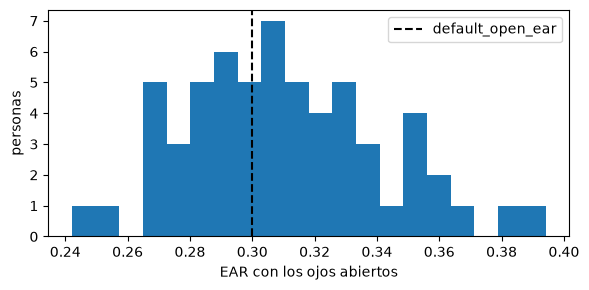

In [3]:
alert_video = videos[videos["label"] == 0].set_index("participant")["video"]
participants = sorted(videos["participant"].unique())
BASELINES = {
    "raw": {p: default_baseline(cfg.calibration.default_open_ear) for p in participants},
    "calibrated": {p: calibration(frames[alert_video[p]], cfg.windows.fps, cfg.calibration.seconds,
                                  cfg.calibration.open_percentile) for p in participants},
}
MODES = {"raw": "Sin calibrar", "calibrated": "Calibrado"}

open_ear = [baseline["ear"] for baseline in BASELINES["calibrated"].values()]
plt.figure(figsize=(6, 3))
plt.hist(open_ear, bins=20)
plt.axvline(cfg.calibration.default_open_ear, color="k", ls="--", label="default_open_ear")
plt.xlabel("EAR con los ojos abiertos")
plt.ylabel("personas")
plt.legend()
plt.tight_layout()
plt.show()

### 2.3 Ventanas y _features_

Cada vídeo se divide en **ventanas del mismo tamaño** que avanzan de 10 en 10 segundos. Dentro de cada ventana, un fotograma cuenta como **ojo cerrado** cuando el EAR baja del 70 % de la referencia (`closed_fraction`). Con eso, se calculan 12 _features_ por ventana:

- `perclos`: fracción del tiempo con los ojos cerrados.
- `blinks_per_min`: parpadeos por minuto (al menos 2 fotogramas).
- `blink_mean` y `blink_std`: media y varianza del tiempo de parpadeo (s).
- `blink_interval`: tiempo medio entre parpadeos (s).
- `long_blinks`: parpadeos de más de 400 ms.
- `ear_mean` y `ear_std`: media y variación de apertura de los ojos.
- `yawns`: bostezos, (boca abierta durante más de 1.5s).
- `pitch_std` y `nods`: cabeceos verticales u horizontales.
- `no_face`: fotogramas sin cara detectada.

Todos los modelos trabajan a partir de estas _features_ excepto la GRU. Esta red recibe los datos originales (12 valores extraídos con MediaPipe) y aprende los patrones que le interesan.

Media de cada _feature_ según el estado (ventana de 30 segundos):

In [4]:
TASKS = {"3class": ("3 clases", CLASSES), "binary": ("Binaria", ("alerta", "somnoliento"))}


@lru_cache(maxsize=None)
def windows_for(mode, seconds):
    return build_windows(videos, frames, BASELINES[mode], seconds, cfg)


def task_data(mode, seconds, task):
    table, sequences = windows_for(mode, seconds)
    if task == "3class":
        return table, sequences, table["label"].to_numpy()
    keep = (table["label"] != 1).to_numpy()
    return table[keep].reset_index(drop=True), sequences[keep], (table["label"][keep] == 2).to_numpy().astype(int)


table, _ = windows_for("calibrated", cfg.windows.seconds)
display(table.groupby("label")[WINDOW_FEATURES].mean().set_axis(CLASSES).T.style.format(precision=3))

,alerta,poco atento,somnoliento
perclos,0.066,0.123,0.271
blinks_per_min,13.671,18.267,18.128
blink_mean,0.268,0.484,2.362
blink_std,0.118,0.285,0.933
blink_interval,9.472,6.003,6.136
long_blinks,0.640,1.475,2.555
ear_mean,0.893,0.862,0.767
ear_std,0.109,0.144,0.160
yawns,0.000,0.023,0.028
pitch_std,1.577,1.929,2.192


## 3. Modelos y entrenamiento

### 3.1 Modelos

* **Reglas:** solo se basa en el análisis de 1 _feature_. En este caso, se analizan la efectividad de PERCLOS (duración media del parpadeo) y la detección de parpadeos largos. Esta técnica es la primera que se empezó a utilizar para problemas de esta índole.
* **Modelos Clásicos**: SVM RBF, Random Forest y Gradient Boosting sobre las _features_ precomputadas de la ventana.
* **GRU:** red recurrente que aprende en base a los fotogramas de la ventana. Parte de las mismas señales que los modelos clásicos, pero deduce las _features_ tras detectar patrones.

El _dataset_ viene dividido en 5 _folds_. El entrenamiento se repite 5 veces para formar un _5-fold_. En cada repetición, un _fold_ distinto se reserva como **_test_** y los otros 4 forman el **_train_**. Además, siguiendo las convenciones en el uso de _k-folds_, se separa 1 de los _folds_ de entrenamiento para la validación. Concretamente para cada modelo:

* **Modelos clásicos**: `GridSearchCV` prueba varias combinaciones de hiperparámetros. Cada prueba entrena con 3 de los 4 _folds_ de _train_ y se valida con el restante, rotando cuál se deja fuera.
* **GRU**: entrena con 3 de los 4 _folds_ de _train_ y, tras cada época, mide el F1-macro en el restante. Se utilizan _early stopping_, AdamW, _warm-up_ y pesado por clase.

Los parámetros de cada experimento realizado se guarda en `weights/drowsiness/`. Sus resultados se encuentran en `results`.

Entrenamiento de los modelos clásicos:

In [5]:
results = {}


def fold_mask(table, fold):
    return (table["fold"] == fold).to_numpy()


def train_classical(model, grid, table, labels):
    features, runs = table[WINDOW_FEATURES], []
    for fold in FOLDS:
        test = fold_mask(table, fold)
        train = ~test
        start = time.time()
        fitted = fit_tuned(model, grid, features[train], labels[train], table["fold"][train])
        runs.append({"model": fitted, "seconds": time.time() - start, "test_pred": fitted.predict(features[test])})
    return runs

Entrenamiento del modelo GRU:

In [6]:
def input_stats(x, whole_video):
    steps = x[x[..., -1] == 1][:, :-1] if whole_video else x
    steps = steps.reshape(-1, steps.shape[-1])
    return steps.mean(0), steps.std(0) + 1e-6


def new_gru(x, labels, whole_video):
    mean, std = input_stats(x, whole_video)
    gru = VideoGRU if whole_video else DrowsinessGRU
    return gru(mean, std, cfg.gru.hidden, cfg.gru.layers, cfg.gru.dropout, labels.max() + 1).cuda()


def class_weights(labels, train):
    weights = compute_class_weight("balanced", classes=np.unique(labels), y=labels[train])
    return torch.tensor(weights, dtype=torch.float32).cuda()


def new_trainer(model, weights, tag, fold):
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.gru.lr, weight_decay=cfg.gru.weight_decay)
    return Trainer(model, optimizer, nn.CrossEntropyLoss(weight=weights), nn.Identity(), nn.Identity(),
                   WEIGHTS_DIR / "checkpoint.pt", cfg.gru.patience, SummaryWriter(str(RUNS_DIR / f"{tag}_fold{fold}")))


def train_gru(table, sequences, labels, tag, whole_video):
    batch_size = cfg.gru.video_batch_size if whole_video else cfg.gru.batch_size
    runs = []
    for i, fold in enumerate(FOLDS):
        val_fold = FOLDS[(i + 1) % len(FOLDS)]
        test, val = fold_mask(table, fold), fold_mask(table, val_fold)
        train = ~(test | val)
        seed_everything(cfg.seed + fold)
        model = new_gru(sequences[train], labels, whole_video)
        trainer = new_trainer(model, class_weights(labels, train), tag, fold)
        start = time.time()
        trainer.fit(GPUBatchLoader(sequences[train], labels[train], batch_size, train=True, seed=cfg.seed + fold),
                    GPUBatchLoader(sequences[val], labels[val], batch_size), cfg.gru.epochs, cfg.gru.warmup_epochs)
        predictor = SequencePredictor(model)
        runs.append({"model": predictor, "seconds": time.time() - start, "test_pred": predictor.predict(sequences[test])})
    return runs

Selección del modelo a entrenar:

In [7]:
CLASSICAL = classical_models(cfg.classical, cfg.seed)
MODELS = [*CLASSICAL, "GRU"]


def train(name, table, sequences, labels, tag, whole_video):
    if name == "GRU":
        return train_gru(table, sequences, labels, tag, whole_video)
    return train_classical(*CLASSICAL[name], table, labels)

Métricas por ventana y por vídeo de cada experimento:

In [8]:
def video_vote(table, labels, predictions):
    votes = pd.DataFrame({"participant": table["participant"], "true": labels, "pred": predictions})
    votes = votes.groupby(["participant", "true"])["pred"].agg(lambda p: p.mode()[0]).reset_index()
    return votes["true"].to_numpy(), votes["pred"].to_numpy()


def evaluate(table, true, pred, class_names):
    video_true, video_pred = video_vote(table, true, pred)
    return {"window": classification_metrics(true, pred, class_names),
            "video": classification_metrics(video_true, video_pred, class_names)}


def window_name(seconds):
    return f"{seconds}s" if seconds else "video"


def run_tag(mode, task, seconds, name):
    return f"{mode}_{task}_{window_name(seconds)}_{name.replace(' ', '_').lower()}"


def run_cached(mode, task, seconds, name):
    table, sequences, labels = task_data(mode, seconds, task)
    tag = run_tag(mode, task, seconds, name)
    runs = cached(WEIGHTS_DIR / f"{tag}.joblib", lambda: train(name, table, sequences, labels.astype(np.int64), tag, seconds is None))
    for run, fold in zip(runs, FOLDS):
        test = fold_mask(table, fold)
        run.update(evaluate(table[test], labels[test], run["test_pred"], TASKS[task][1]))
    results[(mode, task, seconds, name)] = runs

### 3.2 Entrenamiento

Cada modelo se entrena [con y sin calibración](#22-calibración-por-persona), con el tamaño de ventana por defecto (30 s) y en dos tareas:

- **3 clases:** alerta, poca atención y somnolencia.
- **Binaria:** únicamente alerta y somnolencia.

In [9]:
for mode in MODES:
    for task in ("3class", "binary"):
        for name in MODELS:
            run_cached(mode, task, cfg.windows.seconds, name)

## 4. Resultados

### 4.1 Tasa de acierto

F1-macro, media ± desviación típica entre los 5 _folds_ de test, en las dos tareas definidas [en la sección 3.2](#32-entrenamiento):

In [10]:
def mean_std(runs, level):
    values = [run[level]["f1_macro"] for run in runs]
    return f"{np.mean(values):.3f} ± {np.std(values):.3f}"


LEVELS = {"window": "Ventana", "video": "Vídeo"}
for level, level_name in LEVELS.items():
    f1 = pd.DataFrame({(TASKS[task][0], MODES[mode]):
                       {name: mean_std(results[(mode, task, cfg.windows.seconds, name)], level) for name in MODELS}
                       for task in TASKS for mode in MODES})
    f1.to_csv(RESULTS_DIR / f"acierto_{level}.csv")
    print(f"F1-macro por {level_name.lower()}")
    display(f1)

F1-macro por ventana


3 clases                       Binaria               
                Sin calibrar      Calibrado   Sin calibrar      Calibrado
Reglas         0.487 ± 0.030  0.482 ± 0.049  0.689 ± 0.051  0.708 ± 0.074
SVM            0.483 ± 0.039  0.492 ± 0.048  0.698 ± 0.054  0.701 ± 0.050
Random Forest  0.468 ± 0.034  0.507 ± 0.041  0.687 ± 0.029  0.717 ± 0.049
Boosting       0.463 ± 0.024  0.504 ± 0.038  0.690 ± 0.030  0.710 ± 0.034
GRU            0.425 ± 0.020  0.483 ± 0.032  0.667 ± 0.044  0.750 ± 0.042

F1-macro por vídeo


3 clases                       Binaria               
                Sin calibrar      Calibrado   Sin calibrar      Calibrado
Reglas         0.488 ± 0.027  0.518 ± 0.087  0.730 ± 0.059  0.737 ± 0.090
SVM            0.551 ± 0.045  0.518 ± 0.071  0.761 ± 0.060  0.724 ± 0.088
Random Forest  0.523 ± 0.062  0.571 ± 0.070  0.720 ± 0.022  0.781 ± 0.055
Boosting       0.468 ± 0.030  0.552 ± 0.079  0.727 ± 0.062  0.755 ± 0.068
GRU            0.437 ± 0.042  0.515 ± 0.031  0.663 ± 0.056  0.779 ± 0.039

### 4.2 Matrices de confusión

Ejemplo de las matrices de confusión por ventana de las 3 clases, habiendo realizado calibración.

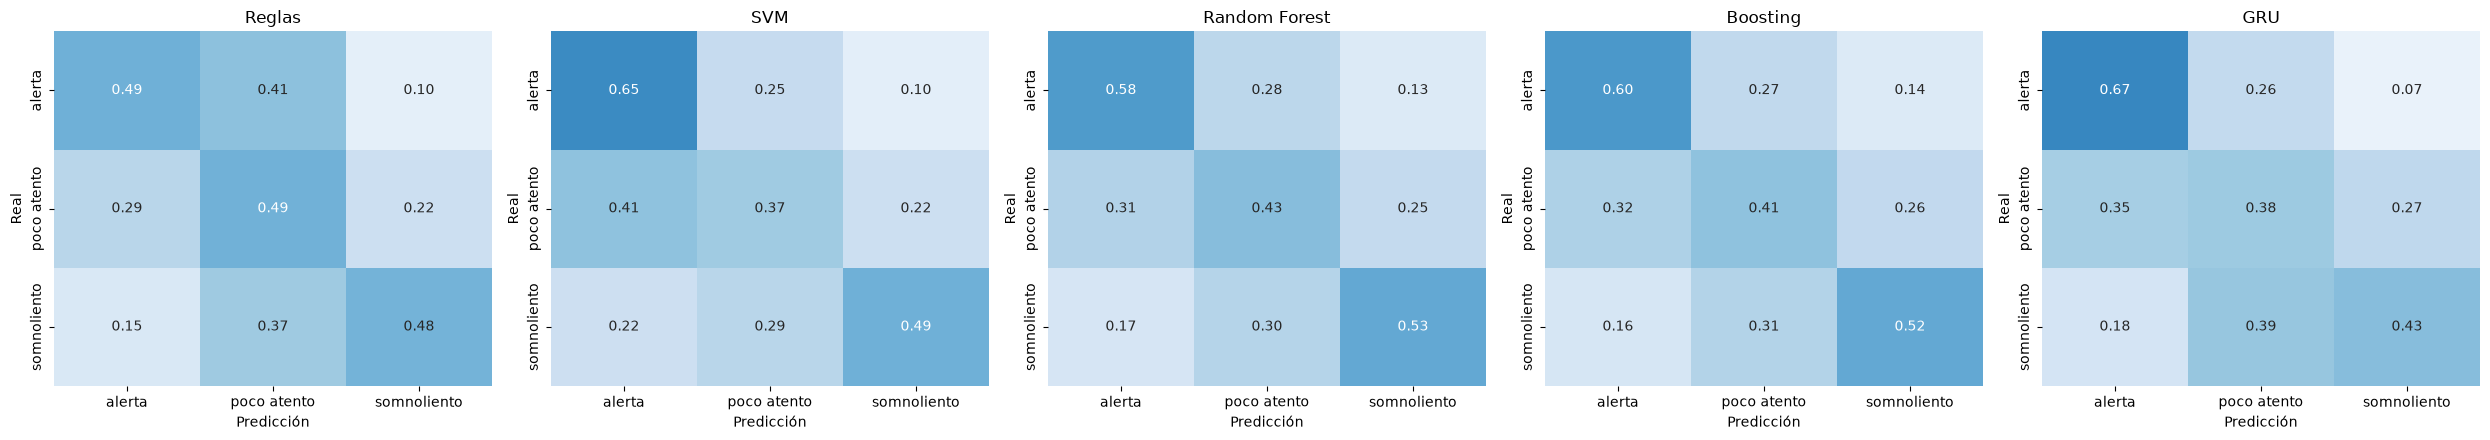

In [11]:
table, _, labels = task_data("calibrated", cfg.windows.seconds, "3class")
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.5))
for ax, name in zip(axes, MODELS):
    runs = results[("calibrated", "3class", cfg.windows.seconds, name)]
    true = np.concatenate([labels[(table["fold"] == fold).to_numpy()] for fold in FOLDS])
    plot_confusion_matrix(true, np.concatenate([run["test_pred"] for run in runs]), CLASSES, name, ax)
plt.savefig(RESULTS_DIR / "matrices_confusion.png", dpi=120)
plt.show()

### 4.3 Duración de la ventana

La duración de la ventana es un hiperparámetro a ajustar. Una ventana más larga contiene más parpadeos, por lo que los resultados obtenidos son más robustos, pero el tiempo de respuesta es menos inmediato.

Para estudiarlo, se analiza el entrenamiento en 3 clases y con calibración, con ventanas de 10, 30, 60 y 120 s, y con el vídeo entero como ventana única. Esta última opción tiene dos particularidades:

- Solo hay 1 muestra por vídeo, por lo que hay pocos datos para entrenar, pudiendo causar peores resultados.
- La GRU recibe cada vídeo completo. Como los vídeos tienen distinta duración, los más cortos se rellenan con ceros hasta igualar al más largo. Se procesan en lotes de 16 vídeos, en lugar de 64 ventanas, porque cada muestra es mucho mayor.

F1-macro según la duración de la ventana:

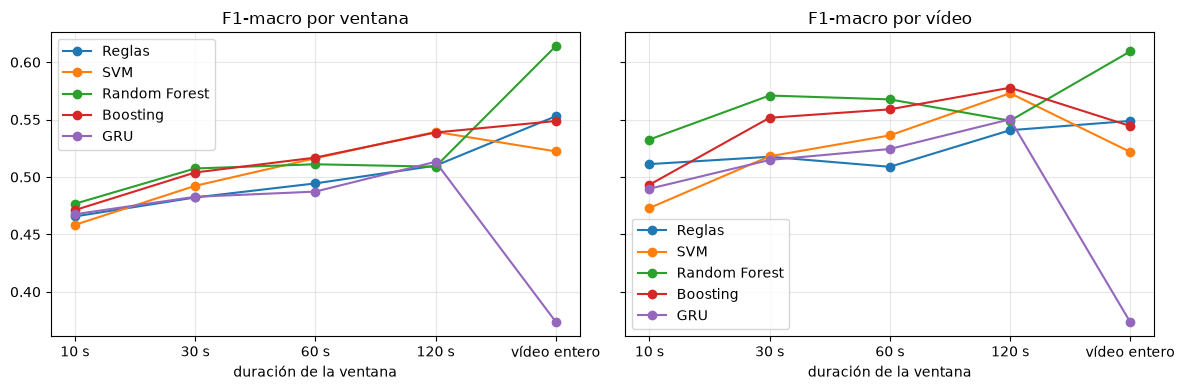

In [12]:
for seconds in cfg.windows.sweep:
    for name in MODELS:
        if ("calibrated", "3class", seconds, name) not in results:
            run_cached("calibrated", "3class", seconds, name)


def sweep_f1(seconds, name, level):
    return np.mean([run[level]["f1_macro"] for run in results[("calibrated", "3class", seconds, name)]])


sweep = pd.DataFrame({(LEVELS[level], name): [sweep_f1(seconds, name, level) for seconds in cfg.windows.sweep]
                      for level in LEVELS for name in MODELS},
                     index=[f"{seconds} s" if seconds else "vídeo entero" for seconds in cfg.windows.sweep])
sweep.to_csv(RESULTS_DIR / "duracion_ventana.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, level in zip(axes, LEVELS.values()):
    sweep[level].plot(ax=ax, marker="o")
    ax.set_xticks(range(len(sweep)), sweep.index)
    ax.set(title=f"F1-macro por {level.lower()}", xlabel="duración de la ventana")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "duracion_ventana.png", dpi=120)
plt.show()

### 4.4 Importancia de las _features_

Para saber en qué _features_ se apoyan los modelos, se calcula su importancia por permutación. Para cada _feature_, se desordenan al azar sus valores en las distintas ventanas y se mide el cambio producido en el F1-macro del modelo. La fluctuación de esta métrica indica la dependencia del modelo sobre esta _feature_.

Se calcula para Random Forest y Boosting (3 clases, calibrado, 30 s), los 2 mejores modelos clásicos, utilizando _5-fold_:

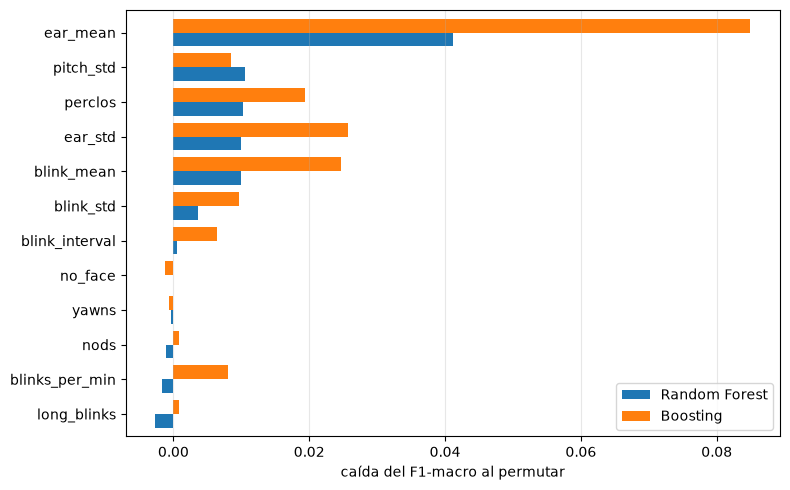

In [13]:
table, _, labels = task_data("calibrated", cfg.windows.seconds, "3class")


def importance(name):
    runs = results[("calibrated", "3class", cfg.windows.seconds, name)]
    scores = []
    for run, fold in zip(runs, FOLDS):
        test = (table["fold"] == fold).to_numpy()
        scores.append(permutation_importance(run["model"], table[WINDOW_FEATURES][test], labels[test], scoring="f1_macro",
                                             n_repeats=5, random_state=cfg.seed, n_jobs=-1).importances_mean)
    return pd.Series(np.mean(scores, 0), index=WINDOW_FEATURES)


importances = cached(WEIGHTS_DIR / "importancia.joblib",
                     lambda: pd.DataFrame({name: importance(name) for name in ("Random Forest", "Boosting")}))
importances.to_csv(RESULTS_DIR / "importancia.csv")
importances.sort_values("Random Forest").plot.barh(figsize=(8, 5), width=0.8)
plt.xlabel("caída del F1-macro al permutar")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "importancia.png", dpi=120)
plt.show()

### 4.5 Coste

Otro de los elementos a tener en cuenta en el análisis de un modelo es el coste de uso. Este se analiza de 2 formas distintas:
- **Por cada fotograma:** extracción de los _landmarks_ de la cara con MediaPipe. Su coste se mide en [`drowsiness_extraction.ipynb`](./drowsiness_extraction.ipynb#4-coste-de-mediapipe).
- **Por cada predicción:** se toman los últimos 30 s de fotogramas, se calculan las _features_ de la ventana y se pasan por el modelo.

La tabla recoge, para cada modelo (3 clases, calibrado, 30 s):

- **Entrenamiento (s/fold):** tiempo medio para entrenar un _fold_, incluyendo la búsqueda de hiperparámetros en los modelos clásicos.
- **Tamaño (KB):** peso del modelo guardado.
- **Features ventana (ms):** tiempo de cálculo de las _features_ de una ventana. Es el mismo para todos los modelos que las usan, y no se aplica a la GRU.
- **Predicción CPU y GPU (ms):** tiempo que tarda el modelo en clasificar una ventana. Los modelos clásicos solo se ejecutan en CPU; la GRU se mide en ambos.

Así, el coste de una predicción en la demostración es el resultado de calcular las _features_ sumado al de la predicción del modelo.

In [14]:
table, sequences, _ = task_data("calibrated", cfg.windows.seconds, "3class")
first = table.iloc[0]
window = {name: values[:cfg.windows.seconds * cfg.windows.fps]
          for name, values in normalise(frames[first.video], BASELINES["calibrated"][first.participant]).items()}
features_ms = measure_latency(lambda: window_features(window, cfg.windows.fps, cfg.events), cfg.timing.iters, cfg.timing.warmup)["mean_ms"]


def predictors(name, model):
    if name == "GRU":
        cpu = SequencePredictor(copy.deepcopy(model.model).cpu())
        return {"CPU": (cpu, sequences[:1]), "GPU": (model, sequences[:1])}
    return {"CPU": (model, table[WINDOW_FEATURES][:1])}


cost = {}
for name in MODELS:
    runs = results[("calibrated", "3class", cfg.windows.seconds, name)]
    model = runs[0]["model"]
    row = {"Entrenamiento (s/fold)": np.mean([run["seconds"] for run in runs]),
           "Tamaño (KB)": len(pickle.dumps(model)) / 1e3,
           "Features ventana (ms)": np.nan if name == "GRU" else features_ms}
    for device, (predictor, x) in predictors(name, model).items():
        sync = torch.cuda.synchronize if device == "GPU" else None
        row[f"Predicción {device} (ms)"] = measure_latency(lambda: predictor.predict(x), cfg.timing.iters, cfg.timing.warmup, sync)["mean_ms"]
    cost[name] = row
cost = pd.DataFrame(cost).T
cost.to_csv(RESULTS_DIR / "coste.csv")
display(cost.style.format(precision=2, na_rep="—"))

,Entrenamiento (s/fold),Tamaño (KB),Features ventana (ms),Predicción CPU (ms),Predicción GPU (ms)
Reglas,0.39,0.41,0.08,0.01,—
SVM,8.95,951.63,0.08,0.70,—
Random Forest,4.14,10450.25,0.08,8.82,—
Boosting,1.67,277.09,0.08,1.63,—
GRU,7.49,1284.34,—,17.41,1.04


## 5. Conclusiones

El modelo escogido debe responder de forma correcta rápida, para poder ser ejecutado en tiempo real.

El escogido, en este caso, para la detección de cansancio es **Random Forest** tras haber sido calibrado. Este es el modelo con mejores resultados de todos los probados, incluso por encima de soluciones de _deep learning_. Al no contar con cantidad ni variabilidad suficiente de los datos, la GRU no es capaz de abstraerse ni detectar patrones con facilidad.

Se destaca, asimismo, la importancia de incluir calibración. Puesto que la _feature_ más importante (apertura media de los ojos) es muy variable según la persona, es imprescindible calibrar el detector antes de estimar para poder obtener resultados fiables. Es por ello que la demostración debe empezar calibrándose.

Se corrobora igualmente el análisis de que ventanas más largas generan mejores resultados, aunque tardan más en proporcionarlos. Por esto, en la demostración se utiliza una ventana de tamaño creciente, en el ánimo de obtener benefcios de los distintos tamaños existentes.